# Assignment 04: Predicting Used-Vehicle Prices

## Aim
Estimate vehicle resale prices from a mixture of numerical specifications and categorical attributes.

## Regression Models
1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² score

The same preprocessing pipeline is applied before comparing the regression models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
np.random.seed(17)

n = 620

brands = np.random.choice(
    [
        "Toyota",
        "Honda",
        "Ford",
        "BMW",
        "Hyundai"
    ],
    n,
    p=[
        0.25,
        0.22,
        0.20,
        0.13,
        0.20
    ]
)

brand_premium = {
    "Toyota": 0,
    "Honda": 500,
    "Ford": -500,
    "BMW": 8000,
    "Hyundai": -1000
}

age = np.random.uniform(
    0,
    15,
    n
)

mileage = (
    age
    * np.random.uniform(
        8000,
        16000,
        n
    )
)

engine = np.random.uniform(
    1.0,
    4.0,
    n
)

fuel = np.random.choice(
    [
        "Petrol",
        "Diesel",
        "Electric"
    ],
    n,
    p=[
        0.5,
        0.35,
        0.15
    ]
)

fuel_premium = np.where(
    fuel == "Electric",
    4000,
    np.where(
        fuel == "Diesel",
        800,
        0
    )
)

base_price = (
    28000
    - age * 1400
    - mileage * 0.04
    + engine * 1500
)

price = (
    base_price
    + np.array([
        brand_premium[b]
        for b in brands
    ])
    + fuel_premium
    + np.random.normal(
        0,
        1200,
        n
    )
)

price = np.clip(
    price,
    1500,
    None
)

veh_df = pd.DataFrame({
    "brand": brands,
    "age_years": age,
    "mileage_km": mileage,
    "engine_size_L": engine,
    "fuel_type": fuel,
    "price": price
})

display(
    veh_df.head()
)

,brand,age_years,mileage_km,engine_size_L,fuel_type,price
0,Honda,9.539158,88717.856699,3.380837,Diesel,17187.877590
1,Ford,7.148544,90621.384587,3.293986,Petrol,17446.746052
2,Toyota,7.707571,96275.023306,3.838287,Diesel,20698.819174
3,Toyota,5.816416,62966.340881,2.500496,Petrol,21965.227610
4,BMW,8.562398,108901.655443,2.397519,Diesel,23361.905837


In [3]:
print("Shape:", veh_df.shape)

print("\nData Types:")
print(veh_df.dtypes)

print("\nSummary:")
display(
    veh_df.describe()
)

Shape: (620, 6)

Data Types:
brand             object
age_years        float64
mileage_km       float64
engine_size_L    float64
fuel_type         object
price            float64
dtype: object

Summary:


,age_years,mileage_km,engine_size_L,price
count,620.000000,620.000000,620.000000,620.000000
mean,7.514359,90040.056980,2.540431,19390.049177
std,4.241966,55009.720948,0.862798,8894.053136
min,0.029709,462.887117,1.000285,1500.000000
25%,4.005384,46317.646148,1.804185,12513.050521
50%,7.551397,86385.802868,2.589231,19082.076261
75%,11.129692,130171.082985,3.293871,26605.404376
max,14.972419,235687.636519,3.980762,40991.521330


In [4]:
num_feats = [
    "age_years",
    "mileage_km",
    "engine_size_L"
]

cat_feats = [
    "brand",
    "fuel_type"
]

In [5]:
preprocess = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        num_feats
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore"
        ),
        cat_feats
    )
])

In [6]:
X = veh_df.drop(
    columns=["price"]
)

y = veh_df["price"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=17
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 496
Testing samples: 124


In [8]:
models = {

    "Linear Regression":
        LinearRegression(),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=280,
            random_state=17
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            random_state=17
        )
}

In [9]:
results = {}

trained_models = {}

predictions = {}

for name, model in models.items():

    pipe = Pipeline([
        (
            "prep",
            preprocess
        ),
        (
            "model",
            model
        )
    ])

    pipe.fit(
        X_train,
        y_train
    )

    preds = pipe.predict(
        X_test
    )

    results[name] = {

        "MAE":
            mean_absolute_error(
                y_test,
                preds
            ),

        "RMSE":
            mean_squared_error(
                y_test,
                preds
            ) ** 0.5,

        "R2":
            r2_score(
                y_test,
                preds
            )
    }

    trained_models[name] = pipe

    predictions[name] = preds

In [10]:
results_df = pd.DataFrame(
    results
).T

display(
    results_df.round(2)
)

,MAE,RMSE,R2
Linear Regression,929.41,1175.26,0.98
Random Forest,1331.13,1673.24,0.97
Gradient Boosting,1153.40,1424.82,0.98


In [11]:
best_model_name = results_df[
    "RMSE"
].idxmin()

print(
    "Model with lowest RMSE:",
    best_model_name
)

Model with lowest RMSE: Linear Regression


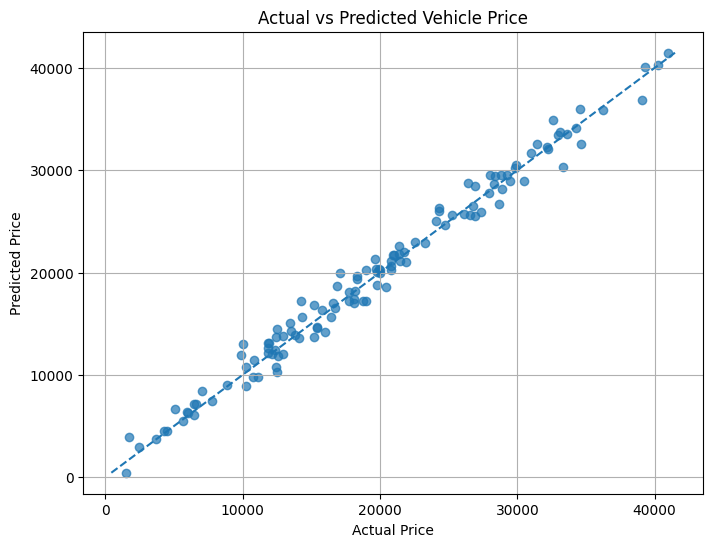

In [12]:
best_preds = predictions[
    best_model_name
]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_preds,
    alpha=0.7
)

min_value = min(
    y_test.min(),
    best_preds.min()
)

max_value = max(
    y_test.max(),
    best_preds.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Price"
)

plt.ylabel(
    "Predicted Price"
)

plt.title(
    "Actual vs Predicted Vehicle Price"
)

plt.grid(True)

plt.show()